In [1]:
root = '/content/data_gtfs'

In [2]:
import os

os.listdir(root)

['calendar.txt',
 'stops.txt',
 'feed_info.txt',
 'routes.txt',
 'trips.txt',
 'agency.txt',
 'stop_times.txt']

In [3]:
import pandas as pd

df = pd.read_csv(root + '/stops.txt')
display(df.head(5))

,stop_id,stop_name,stop_lat,stop_lon
0,KDMT_3,Kalyan Station,19.23673,73.13028
1,KDMT_44,Rambagh,19.24361,73.13043
2,KDMT_45,NSC Bose Chowk/Baicha Putla,19.24227,73.13659
3,KDMT_53,State Bank,19.24226,73.13976
4,KDMT_54,State Bank,19.24214,73.13972


In [4]:
from shapely.geometry import Point

In [5]:
import geopandas as gpd

In [6]:
geometry = [Point(xy) for xy in zip(df['stop_lon'],df['stop_lat'])]

In [7]:
geometry[0:5]

[<POINT (73.13 19.237)>,
 <POINT (73.13 19.244)>,
 <POINT (73.137 19.242)>,
 <POINT (73.14 19.242)>,
 <POINT (73.14 19.242)>]

In [12]:
gdf=df.copy()
gdf['geometry'] = geometry
type(gdf)

pandas.core.frame.DataFrame

In [13]:
gdf=gpd.GeoDataFrame(gdf)
type(gdf)

geopandas.geodataframe.GeoDataFrame

In [14]:
gdf.head()

,stop_id,stop_name,stop_lat,stop_lon,geometry
0,KDMT_3,Kalyan Station,19.23673,73.13028,POINT (73.13028 19.23673)
1,KDMT_44,Rambagh,19.24361,73.13043,POINT (73.13043 19.24361)
2,KDMT_45,NSC Bose Chowk/Baicha Putla,19.24227,73.13659,POINT (73.13659 19.24227)
3,KDMT_53,State Bank,19.24226,73.13976,POINT (73.13976 19.24226)
4,KDMT_54,State Bank,19.24214,73.13972,POINT (73.13972 19.24214)


<Axes: xlabel='x', ylabel='y'>

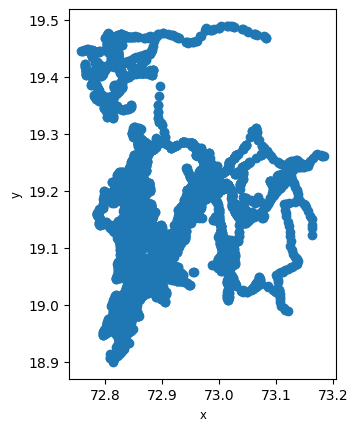

In [15]:
gdf.plot()

In [17]:
import matplotlib.pyplot as plt


(np.float64(72.73774915000001),
 np.float64(73.20533384999999),
 np.float64(18.870619),
 np.float64(19.518475))

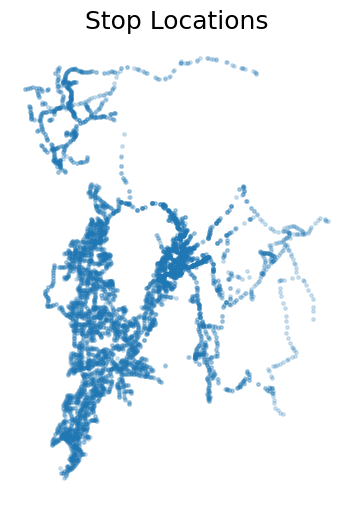

In [20]:
f, ax = plt.subplots(1,1,figsize=(6,6))
ax.set_title('Stop Locations',fontsize=18)
gdf.plot(ax=ax, alpha=0.2,markersize=6)
ax.axis('off')